In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import time

from sklearn.model_selection import TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import KNNImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 23
np.random.seed(SEED)

In [2]:
pd.set_option("display.max_columns", None)

BLUE, TEAL, AMBER, CORAL = "#2F5D8C", "#2A9D8F", "#E9A23B", "#D1603D"
SLATE = "#2B3A4A"
PALETTE = [BLUE, TEAL, AMBER, CORAL]
sns.set_theme(
    style="whitegrid", palette=PALETTE,
    rc={"figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#B8C2CC",
        "grid.color": "#E6EAEE", "axes.titleweight": "bold", "axes.titlecolor": SLATE,
        "axes.labelcolor": SLATE, "text.color": SLATE, "xtick.color": SLATE, "ytick.color": SLATE},
)

In [3]:
df = pd.read_csv("../data/train-test.csv", parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)
print(df.shape, df["date"].min().date(), "to", df["date"].max().date())

(48000, 14) 2025-01-01 to 2025-10-31


## Train-Test Split (Time-based)

In [4]:
CUTOFF = pd.Timestamp("2025-09-01")

train = df[df["date"] < CUTOFF].copy()
test = df[df["date"] >= CUTOFF].copy()

print(f"Train: {len(train):,} rows ({len(train) / len(df):.1%}), "
      f"{train['date'].min().date()} to {train['date'].max().date()}")
print(f"Test:  {len(test):,} rows ({len(test) / len(df):.1%}), "
      f"{test['date'].min().date()} to {test['date'].max().date()}")

assert train["date"].max() < test["date"].min()  # no overlap in time

Train: 38,477 rows (80.2%), 2025-01-01 to 2025-08-31
Test:  9,523 rows (19.8%), 2025-09-01 to 2025-10-31


## Cross-Validation folds

In [5]:
train = train.reset_index(drop=True)
dates = np.sort(train["date"].unique())

tscv = TimeSeriesSplit(n_splits=5)
cv_folds = []
for tr_d, va_d in tscv.split(dates):
    tr_idx = train.index[train["date"].isin(dates[tr_d])].to_numpy()
    va_idx = train.index[train["date"].isin(dates[va_d])].to_numpy()
    cv_folds.append((tr_idx, va_idx))

for i, (tr_idx, va_idx) in enumerate(cv_folds, 1):
    print(f"Fold {i}: train {train.loc[tr_idx, 'date'].min().date()} to {train.loc[tr_idx, 'date'].max().date()} "
          f"({len(tr_idx):,} rows) | valid {train.loc[va_idx, 'date'].min().date()} to "
          f"{train.loc[va_idx, 'date'].max().date()} ({len(va_idx):,} rows)")

Fold 1: train 2025-01-01 to 2025-02-12 (6,819 rows) | valid 2025-02-13 to 2025-03-24 (6,289 rows)
Fold 2: train 2025-01-01 to 2025-03-24 (13,108 rows) | valid 2025-03-25 to 2025-05-03 (6,496 rows)
Fold 3: train 2025-01-01 to 2025-05-03 (19,604 rows) | valid 2025-05-04 to 2025-06-12 (6,305 rows)
Fold 4: train 2025-01-01 to 2025-06-12 (25,909 rows) | valid 2025-06-13 to 2025-07-22 (6,361 rows)
Fold 5: train 2025-01-01 to 2025-07-22 (32,270 rows) | valid 2025-07-23 to 2025-08-31 (6,207 rows)


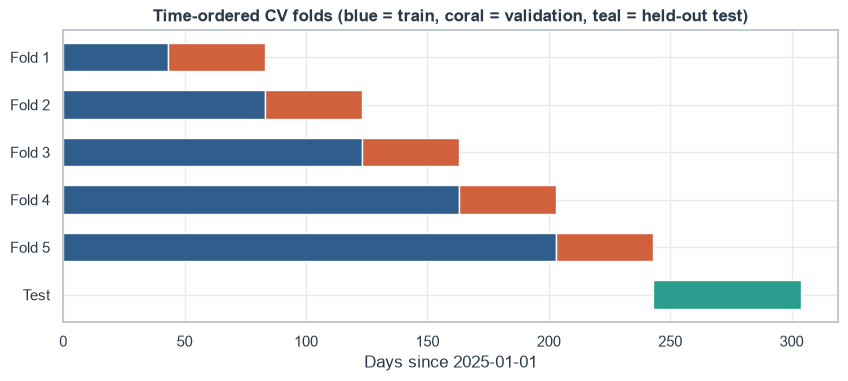

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.8))
d0 = train["date"].min()

for i, (tr_idx, va_idx) in enumerate(cv_folds, 1):
    for idx, color in [(tr_idx, BLUE), (va_idx, CORAL)]:
        start = (train.loc[idx, "date"].min() - d0).days
        end = (train.loc[idx, "date"].max() - d0).days + 1
        ax.barh(i, end - start, left=start, color=color, height=0.6)

t_start = (test["date"].min() - d0).days
t_end = (test["date"].max() - d0).days + 1
ax.barh(len(cv_folds) + 1, t_end - t_start, left=t_start, color=TEAL, height=0.6)

ax.set_yticks(range(1, len(cv_folds) + 2))
ax.set_yticklabels([f"Fold {i}" for i in range(1, len(cv_folds) + 1)] + ["Test"])
ax.invert_yaxis()
ax.set_xlabel("Days since 2025-01-01")
ax.set_title("Time-ordered CV folds (blue = train, coral = validation, teal = held-out test)")
plt.show()

## Preprocessing Pipeline

In [7]:
FEATURES = ["distance", "log_distance", "weight", "market_index", "quote_signal",
            "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "dow", "equipment"]

def make_features(frame):
    out = frame.copy()
    out["weight"] = out["weight"].abs()  # negative weights are sign errors
    out["log_distance"] = np.log(out["distance"])
    out["dow"] = out["date"].dt.dayofweek
    return out[FEATURES]

X_train, y_train = make_features(train), train["posted_rate"].reset_index(drop=True)
X_test, y_test = make_features(test).reset_index(drop=True), test["posted_rate"].reset_index(drop=True)

In [8]:
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print()
print("Missing values left in X_train:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])
print()
print("Negative weights left:", (X_train["weight"] < 0).sum(), "/", (X_test["weight"] < 0).sum())
X_train.head()

X_train: (38477, 11) | X_test: (9523, 11)

Missing values left in X_train:
weight          235
market_index    301
dtype: int64

Negative weights left: 0 / 0


,distance,log_distance,weight,market_index,quote_signal,pickup_lat,pickup_lon,delivery_lat,delivery_lon,dow,equipment
0,274.3,5.614222,30658.0,0.95684,2.39595,38.09122,-76.78906,38.16908,-72.74564,2,Dry Van
1,691.7,6.539152,47500.0,0.95310,2.16789,31.37602,-86.10743,39.62180,-88.48008,2,Dry Van
2,1098.0,7.001246,29071.0,0.96395,1.81827,39.55328,-72.18051,41.70243,-89.85588,2,Dry Van
3,684.1,6.528104,25756.0,0.92209,1.90370,39.55328,-72.18051,34.15334,-79.74475,2,Dry Van
4,891.6,6.793018,21332.0,0.97336,1.78958,28.56624,-116.70249,39.54838,-118.64843,2,Dry Van


In [9]:
NUM = ["distance", "log_distance", "weight", "market_index", "quote_signal",
       "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]
CAT = ["equipment", "dow"]

def make_preprocessor(k=5):
    encode_scale = ColumnTransformer(
        [("num", StandardScaler(), NUM),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)]
    )
    return Pipeline([("encode_scale", encode_scale),
                     ("knn_impute", KNNImputer(n_neighbors=k))])

In [10]:
prep = make_preprocessor()
Z_train = prep.fit_transform(X_train)   # learns scaling, categories and neighbors from train only
Z_test = prep.transform(X_test)         # only applies what was learned

names = prep.named_steps["encode_scale"].get_feature_names_out()
print("Z_train:", Z_train.shape, "| Z_test:", Z_test.shape)
print("NaN left (train / test):", np.isnan(Z_train).sum(), "/", np.isnan(Z_test).sum())
pd.DataFrame(Z_train, columns=names).head()

Z_train: (38477, 19) | Z_test: (9523, 19)
NaN left (train / test): 0 / 0


,num__distance,num__log_distance,num__weight,num__market_index,num__quote_signal,num__pickup_lat,num__pickup_lon,num__delivery_lat,num__delivery_lon,cat__equipment_Dry Van,cat__equipment_Flatbed,cat__equipment_Reefer,cat__dow_0,cat__dow_1,cat__dow_2,cat__dow_3,cat__dow_4,cat__dow_5,cat__dow_6
0,-1.186050,-1.603177,-0.090716,-1.028382,1.161732,0.568200,1.050348,0.584545,1.347504,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,-0.611543,-0.351558,2.019175,-1.051615,0.370970,-0.988693,0.359395,0.920934,0.178767,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,-0.052315,0.273749,-0.289528,-0.984213,-0.841281,0.907172,1.392070,1.402721,0.076574,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.622004,-0.366508,-0.704816,-1.244257,-0.545066,0.907172,1.392070,-0.345333,0.827618,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,-0.336402,-0.008026,-1.259035,-0.925755,-0.940759,-1.640130,-1.909216,0.903933,-2.062105,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## Evaluation Matrix

In [11]:
def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": np.mean(np.abs(y_true - y_pred) / y_true) * 100,
        "WAPE (%)": np.abs(y_true - y_pred).sum() / y_true.sum() * 100,
        "R2": r2_score(y_true, y_pred),
    }

# sanity check: predicting the training median for every load
print(pd.Series(evaluate(y_test, np.full(len(y_test), y_train.median()))).round(2))

MAE         1148.92
RMSE        1569.42
MAPE (%)      70.15
WAPE (%)      48.02
R2            -0.06
dtype: float64


## Baseline Model

In [12]:
def baseline_fit_predict(X_tr, y_tr, X_va):
    rpm = (y_tr / X_tr["distance"]).groupby(X_tr["equipment"]).median()  # learned on the fold's train part only
    return X_va["distance"] * X_va["equipment"].map(rpm)

def cv_scores(fit_predict, X, y, folds):
    rows = []
    for tr_idx, va_idx in folds:
        pred = fit_predict(X.iloc[tr_idx], y.iloc[tr_idx], X.iloc[va_idx])
        rows.append(evaluate(y.iloc[va_idx], pred))
    return pd.DataFrame(rows, index=[f"Fold {i}" for i in range(1, len(folds) + 1)])

In [13]:
cv_baseline = cv_scores(baseline_fit_predict, X_train, y_train, cv_folds)
print(cv_baseline.round(2))
print()
print("Mean over folds:")
print(cv_baseline.mean().round(2))

           MAE    RMSE  MAPE (%)  WAPE (%)    R2
Fold 1  188.94  542.16     10.30      8.15  0.85
Fold 2  186.13  542.31     10.36      7.81  0.86
Fold 3  195.42  571.57     10.83      8.00  0.85
Fold 4  208.69  695.35     10.38      8.50  0.80
Fold 5  242.13  706.19     10.30     10.26  0.78

Mean over folds:
MAE         204.26
RMSE        611.52
MAPE (%)     10.44
WAPE (%)      8.54
R2            0.83
dtype: float64


## Default Models

In [14]:
def make_model(regressor):
    pipe = Pipeline([("prep", make_preprocessor()), ("model", regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)

def sklearn_fit_predict(model):
    def fit_predict(X_tr, y_tr, X_va):
        return clone(model).fit(X_tr, y_tr).predict(X_va)
    return fit_predict

default_models = {
    "Ridge": make_model(Ridge()),
    "Random Forest": make_model(RandomForestRegressor(random_state=SEED, n_jobs=-1)),
    "HistGradientBoosting": make_model(HistGradientBoostingRegressor(random_state=SEED)),
}

In [15]:
cv_by_model = {"Baseline (rate/mile)": cv_baseline}

for name, model in default_models.items():
    t0 = time.time()
    cv_by_model[name] = cv_scores(sklearn_fit_predict(model), X_train, y_train, cv_folds)
    print(f"{name}: {time.time() - t0:.0f}s")

summary = pd.DataFrame({name: s.mean() for name, s in cv_by_model.items()}).T.sort_values("MAE")
summary.round(2)

Ridge: 3s
Random Forest: 15s
HistGradientBoosting: 4s


,MAE,RMSE,MAPE (%),WAPE (%),R2
Ridge,136.20,600.76,6.32,5.69,0.84
HistGradientBoosting,147.70,602.35,6.54,6.18,0.84
Random Forest,178.00,629.89,7.98,7.45,0.82
Baseline (rate/mile),204.26,611.52,10.44,8.54,0.83


## Optuna

In [16]:
N_TRIALS = 30

def make_model(regressor, k=5):
    pipe = Pipeline([("prep", make_preprocessor(k)), ("model", regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)

def cv_mae(model):
    return cv_scores(sklearn_fit_predict(model), X_train, y_train, cv_folds)["MAE"].mean()

def ridge_objective(trial):
    alpha = trial.suggest_float("alpha", 1e-3, 1e3, log=True)
    k = trial.suggest_int("knn_k", 3, 15)
    return cv_mae(make_model(Ridge(alpha=alpha), k=k))

def hgb_objective(trial):
    reg = HistGradientBoostingRegressor(
        loss=trial.suggest_categorical("loss", ["squared_error", "absolute_error"]),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_iter=trial.suggest_int("max_iter", 100, 600),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 8, 64),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 20, 200),
        l2_regularization=trial.suggest_float("l2_regularization", 1e-3, 10, log=True),
        random_state=SEED,
    )
    k = trial.suggest_int("knn_k", 3, 15)
    return cv_mae(make_model(reg, k=k))

In [17]:
ridge_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
ridge_study.optimize(ridge_objective, n_trials=N_TRIALS, show_progress_bar=True)

print("Best CV MAE:", round(ridge_study.best_value, 2))
print(ridge_study.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

Best CV MAE: 115.22
{'alpha': 107.83385427561801, 'knn_k': 11}


In [18]:
hgb_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
hgb_study.optimize(hgb_objective, n_trials=N_TRIALS, show_progress_bar=True)

print("Best CV MAE:", round(hgb_study.best_value, 2))
print(hgb_study.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

Best CV MAE: 122.7
{'loss': 'absolute_error', 'learning_rate': 0.15968975616292932, 'max_iter': 274, 'max_leaf_nodes': 26, 'min_samples_leaf': 98, 'l2_regularization': 0.034086932716089424, 'knn_k': 11}


In [19]:
tuned = pd.DataFrame(
    {"Default CV MAE": [summary.loc["Ridge", "MAE"], summary.loc["HistGradientBoosting", "MAE"]],
     "Tuned CV MAE": [ridge_study.best_value, hgb_study.best_value]},
    index=["Ridge", "HistGradientBoosting"],
)
tuned["Improvement (%)"] = (1 - tuned["Tuned CV MAE"] / tuned["Default CV MAE"]) * 100
tuned.round(2)

,Default CV MAE,Tuned CV MAE,Improvement (%)
Ridge,136.2,115.22,15.41
HistGradientBoosting,147.7,122.70,16.92


## Refit and Final Test Evaluation

In [20]:
rp = ridge_study.best_params
best_ridge = make_model(Ridge(alpha=rp["alpha"]), k=rp["knn_k"])

hp = dict(hgb_study.best_params)
k_hgb = hp.pop("knn_k")
best_hgb = make_model(HistGradientBoostingRegressor(random_state=SEED, **hp), k=k_hgb)

best_ridge.fit(X_train, y_train)
best_hgb.fit(X_train, y_train)
print("Both models refit on", len(X_train), "training rows")

Both models refit on 38477 training rows


In [21]:
rows = []

def add(name, pred_train, cv_mae_value, pred_test):
    tr, te = evaluate(y_train, pred_train), evaluate(y_test, pred_test)
    rows.append({"Model": name, "Train MAE": tr["MAE"], "CV MAE": cv_mae_value, "Test MAE": te["MAE"],
                 "Test RMSE": te["RMSE"], "Test MAPE (%)": te["MAPE (%)"],
                 "Test WAPE (%)": te["WAPE (%)"], "Test R2": te["R2"]})

add("Baseline (rate/mile)",
    baseline_fit_predict(X_train, y_train, X_train), cv_baseline["MAE"].mean(),
    baseline_fit_predict(X_train, y_train, X_test))
add("Ridge (tuned)", best_ridge.predict(X_train), ridge_study.best_value, best_ridge.predict(X_test))
add("HistGradientBoosting (tuned)", best_hgb.predict(X_train), hgb_study.best_value, best_hgb.predict(X_test))

final_results = pd.DataFrame(rows).set_index("Model")
final_results.round(2)

,Train MAE,CV MAE,Test MAE,Test RMSE,Test MAPE (%),Test WAPE (%),Test R2
Model,,,,,,,
Baseline (rate/mile),233.61,204.26,229.10,670.66,10.49,9.58,0.81
Ridge (tuned),100.16,115.22,165.23,650.38,7.07,6.91,0.82
HistGradientBoosting (tuned),82.15,122.70,141.52,643.22,6.03,5.92,0.82


## Error Analysis

In [22]:
err = test.reset_index(drop=True)[["date", "distance", "equipment"]].copy()
err["actual"] = y_test.to_numpy()
err["pred"] = best_hgb.predict(X_test)
err["abs_err"] = (err["pred"] - err["actual"]).abs()
err["pct_err"] = err["abs_err"] / err["actual"] * 100
err["ratio"] = err["actual"] / err["pred"]  # >1 means the model under-predicted
err.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
date,9523,2025-09-30 22:56:02.217788416,2025-09-01 00:00:00,2025-09-16 00:00:00,2025-10-01 00:00:00,2025-10-16 00:00:00,2025-10-31 00:00:00,NaN
distance,9523.0,1135.242613,70.0,542.7,945.8,1635.55,3396.6,736.701237
actual,9523.0,2392.450169,104.38,1243.06,2044.32,3335.735,20361.89,1526.132503
pred,9523.0,2274.937919,214.014185,1211.68643,1978.785694,3192.319546,6518.961754,1322.731105
abs_err,9523.0,141.519682,0.02118,31.820666,64.806605,120.62702,16391.569542,627.490644
pct_err,9523.0,6.027652,0.00139,2.031708,3.472393,5.01438,452.524384,24.222964
ratio,9523.0,1.050863,0.180987,1.019601,1.035178,1.05198,5.381835,0.251697


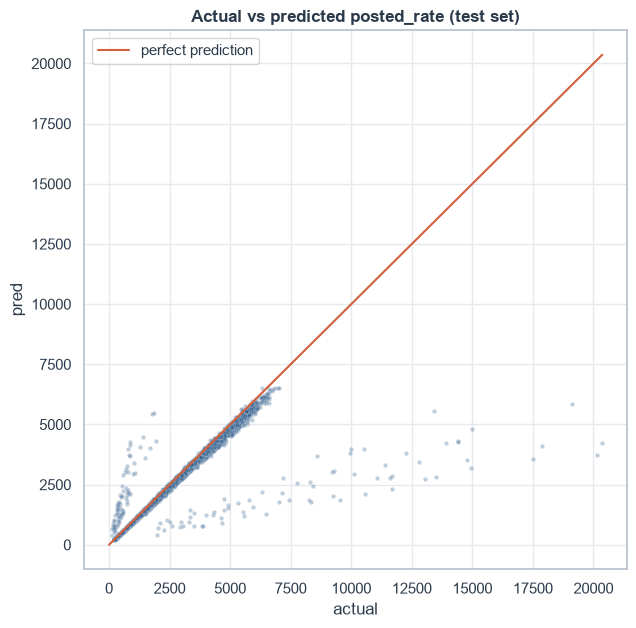

In [23]:
plt.figure(figsize=(7, 7))
sns.scatterplot(data=err, x="actual", y="pred", color=BLUE, alpha=0.3, s=10)
lim = [0, err[["actual", "pred"]].max().max()]
plt.plot(lim, lim, color=CORAL, linewidth=1.5, label="perfect prediction")
plt.title("Actual vs predicted posted_rate (test set)")
plt.legend()
plt.show()

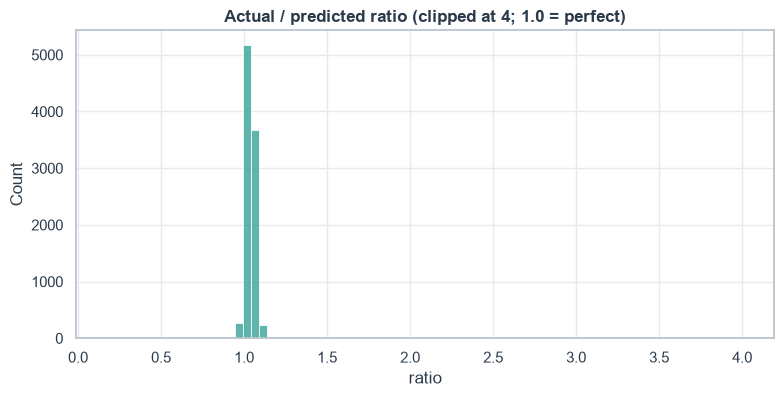

In [24]:
plt.figure(figsize=(9, 4))
sns.histplot(err["ratio"].clip(0, 4), bins=80, color=TEAL)
plt.title("Actual / predicted ratio (clipped at 4; 1.0 = perfect)")
plt.xlabel("ratio")
plt.show()

In [25]:
LOW, HIGH = 0.55, 1.8   # my thresholds, adjust if the histogram suggests different cut-offs
extreme = (err["ratio"] > HIGH) | (err["ratio"] < LOW)

print(f"Extreme loads: {extreme.sum()} ({extreme.mean() * 100:.2f} % of test)")
print(f"Share of total absolute error from them: {err.loc[extreme, 'abs_err'].sum() / err['abs_err'].sum() * 100:.1f} %")
print(f"MAE, all loads:        {err['abs_err'].mean():.2f}")
print(f"MAE, without extremes: {err.loc[~extreme, 'abs_err'].mean():.2f}")
print(f"MAPE, without extremes: {err.loc[~extreme, 'pct_err'].mean():.2f} %")

Extreme loads: 144 (1.51 % of test)
Share of total absolute error from them: 40.0 %
MAE, all loads:        141.52
MAE, without extremes: 86.16
MAPE, without extremes: 3.62 %


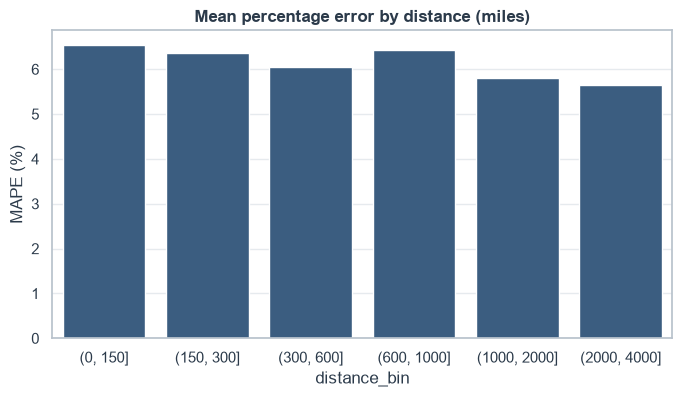

In [26]:
err["distance_bin"] = pd.cut(err["distance"], [0, 150, 300, 600, 1000, 2000, 4000])
by_dist = err.groupby("distance_bin", observed=True)[["abs_err", "pct_err"]].mean().reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=by_dist, x="distance_bin", y="pct_err", color=BLUE)
plt.title("Mean percentage error by distance (miles)")
plt.ylabel("MAPE (%)")
plt.show()

In [27]:
by_eq = err.groupby("equipment")[["abs_err", "pct_err"]].mean().round(2)
by_eq

,abs_err,pct_err
equipment,,
Dry Van,133.98,5.76
Flatbed,148.63,6.67
Reefer,153.15,6.15


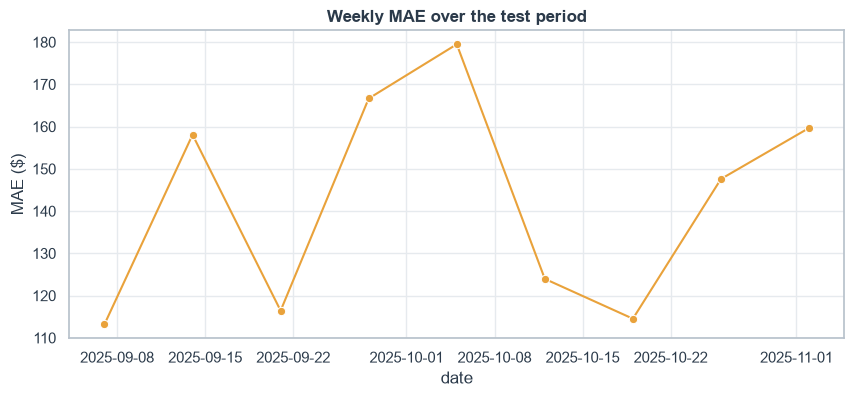

In [28]:
weekly = err.set_index("date")["abs_err"].resample("W").mean()

plt.figure(figsize=(10, 4))
sns.lineplot(x=weekly.index, y=weekly.values, color=AMBER, marker="o")
plt.title("Weekly MAE over the test period")
plt.ylabel("MAE ($)")
plt.show()

## Bias Check

In [29]:
def fold_bias(model, name):
    rows = []
    for i, (tr_idx, va_idx) in enumerate(cv_folds, 1):
        pred = clone(model).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx]).predict(X_train.iloc[va_idx])
        ratio = y_train.iloc[va_idx].to_numpy() / pred
        rows.append({"Model": name, "Fold": f"Fold {i}",
                     "Valid start": train.loc[va_idx, "date"].min().date(),
                     "Median ratio": np.median(ratio)})
    return pd.DataFrame(rows)

bias = pd.concat([fold_bias(best_hgb, "HistGradientBoosting"),
                  fold_bias(best_ridge, "Ridge")], ignore_index=True)
bias.pivot(index="Fold", columns="Model", values="Median ratio").round(3)

Model,HistGradientBoosting,Ridge
Fold,,
Fold 1,1.006,1.022
Fold 2,1.021,0.998
Fold 3,1.007,1.005
Fold 4,1.013,1.023
Fold 5,1.020,1.026


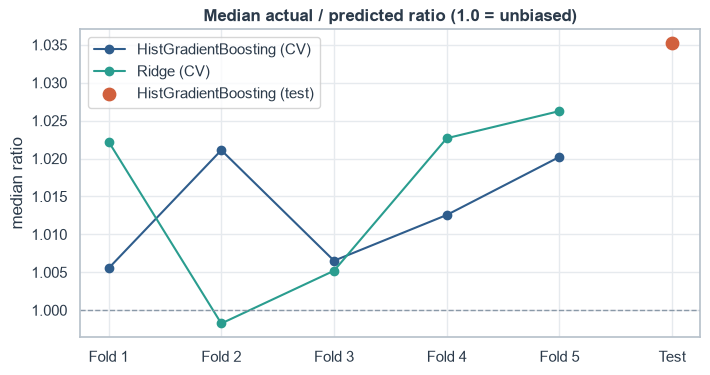

In [30]:
hgb_bias = bias[bias["Model"] == "HistGradientBoosting"]
ridge_bias = bias[bias["Model"] == "Ridge"]
test_ratio = err["ratio"].median()  # already computed in the error analysis

plt.figure(figsize=(8, 4))
plt.plot(hgb_bias["Fold"], hgb_bias["Median ratio"], marker="o", color=BLUE, label="HistGradientBoosting (CV)")
plt.plot(ridge_bias["Fold"], ridge_bias["Median ratio"], marker="o", color=TEAL, label="Ridge (CV)")
plt.scatter(["Test"], [test_ratio], color=CORAL, s=80, zorder=5, label="HistGradientBoosting (test)")
plt.axhline(1.0, color="#8A99A8", linestyle="--", linewidth=1)
plt.title("Median actual / predicted ratio (1.0 = unbiased)")
plt.ylabel("median ratio")
plt.legend()
plt.show()

## Final Fit and Validation Predictions

In [31]:
X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)

final_model = clone(best_hgb).fit(X_all, y_all)
print("Final model fit on", len(X_all), "labeled loads")

Final model fit on 48000 labeled loads


In [32]:
val = pd.read_csv("../data/validation.csv", parse_dates=["date"])
X_val = make_features(val)          # same cleaning and features as training
pred_val = final_model.predict(X_val)

template = pd.read_csv("../data/validation-predictions-template.csv")
submission = pd.DataFrame({"load_id": val["load_id"], "predicted_rate": pred_val.round(2)})
submission = template[["load_id"]].merge(submission, on="load_id", how="left")  # keep the template's order

print("Rows:", len(submission))
print("Missing predictions:", submission["predicted_rate"].isna().sum())
print("Non-positive predictions:", (submission["predicted_rate"] <= 0).sum())
print("Duplicate load_ids:", submission["load_id"].duplicated().sum())
submission["predicted_rate"].describe().round(2)

Rows: 12000
Missing predictions: 0
Non-positive predictions: 0
Duplicate load_ids: 0


count    12000.00
mean      2318.81
std       1342.53
min        207.93
25%       1247.26
50%       1987.60
75%       3311.67
max       6635.36
Name: predicted_rate, dtype: float64

In [33]:
submission.to_csv("../validation_predictions.csv", index=False)
pd.read_csv("../validation_predictions.csv").head()

,load_id,predicted_rate
0,TE-000001,825.75
1,TE-000002,4633.08
2,TE-000003,5180.02
3,TE-000004,4144.06
4,TE-000005,1759.71


## December Chart Predictions

In [34]:
dec = pd.read_csv("../data/december-chart-inputs.csv")
dec_feat = dec.drop(columns="predicted_rate").copy()
dec_feat["date"] = pd.to_datetime(dec_feat["date"])

# coordinates: look up each city in the labeled data
pick = df.drop_duplicates("pickup").set_index("pickup")[["pickup_lat", "pickup_lon"]]
deli = df.drop_duplicates("delivery").set_index("delivery")[["delivery_lat", "delivery_lon"]]
dec_feat = dec_feat.join(pick, on="pickup").join(deli, on="delivery")

# Option A: per-day mean market signals from validation.csv for the same dates
daily_val_signals = val.groupby("date")[["market_index", "quote_signal"]].mean()
dec_feat = dec_feat.join(daily_val_signals, on="date")

print("Rows:", len(dec_feat))
print("Missing values:", dec_feat.isna().sum().sum())
dec_feat.head()

Rows: 31
Missing values: 0


,pickup,delivery,distance,equipment,weight,date,pickup_lat,pickup_lon,delivery_lat,delivery_lon,market_index,quote_signal
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,36.99152,-84.99876,41.31561,-85.36206,0.834919,2.052023
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,36.99152,-84.99876,41.31561,-85.36206,0.914680,2.034115
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,36.99152,-84.99876,41.31561,-85.36206,0.994063,2.053293
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,36.99152,-84.99876,41.31561,-85.36206,1.024021,2.065683
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,36.99152,-84.99876,41.31561,-85.36206,0.975120,2.047368


In [35]:
X_dec = make_features(dec_feat)
dec["predicted_rate"] = final_model.predict(X_dec).round(2)

dec.to_csv("../december-chart-predictions.csv", index=False)
print(dec["predicted_rate"].describe().round(2))
dec.head()

count     31.00
mean     793.49
std        4.98
min      784.03
25%      790.59
50%      793.75
75%      797.45
max      800.57
Name: predicted_rate, dtype: float64


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,787.66
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,794.98
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,796.36
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,795.91
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,797.23


## Key Insights

Split and validation
- The labeled data (Jan 1 to Oct 31) precedes the Nov-Dec predictions, so this is a forecasting task and I split by time. Train: Jan to Aug (38,477 rows, 80.2%). Test: Sep to Oct (9,523 rows, 19.8%), matching the two-month forecast horizon.
- Tuning used 5 expanding-window CV folds built on unique dates, so loads from one day never straddle a train/validation boundary. The test set was scored once, after tuning.
- This departs from the random splits in the course examples, and the reason is the forecasting setup.

Preprocessing (fit on train only)
- Negative weights converted with abs(). Weekday and log-distance added. Locations are represented by coordinates, not city names, because validation has 8 cities unseen in training. Day-of-year was excluded, since Nov-Dec falls outside the training range.
- Scaling and one-hot encoding come first, then a KNN imputer, so neighbors are measured on comparable features. The target is modeled as log(rate) and converted back to dollars.

Model comparison (CV MAE, then test)
- Baseline (median rate per mile by equipment x distance): CV MAE 204, test MAE 229, test MAPE 10.5%.
- Defaults: Ridge 136, HistGradientBoosting 148, Random Forest 178. Random Forest was weakest and slowest, so it was not tuned.
- Optuna (TPE, 30 trials, fixed seed, same folds and metric for both models): Ridge 115 (alpha about 108, KNN k = 11) and HistGradientBoosting 123 (absolute-error loss, k = 11).
- Test MAE (MAPE): Ridge 165 (7.1%), HistGradientBoosting 142 (6.0%). HistGradientBoosting is the final model, a 38% MAE reduction vs the baseline.
- CV slightly favored Ridge, and test favored HistGradientBoosting. Choosing on the test score makes it mildly optimistic.

Error analysis
- 144 loads (1.5% of the test set) cause 40% of the total absolute error. Without them, MAE falls from 142 to 86 and MAPE from 6.0% to 3.6%. These spikes go both above and below the prediction and no feature explains them, so they set a floor on RMSE (about 640) for every model.
- Error is similar across distance bands and equipment types (MAPE roughly 5.6% to 6.7%), so there is no weak segment.

Bias check
- The model under-predicts typical loads by about 3.5% on test (median actual/predicted = 1.035). In CV the median ratio is also above 1.00 in all five folds (1.006 to 1.021) and grows from Fold 3 onward.
- Hypothesis, not tested: rates drift upward in a way our features do not capture. I accepted this and refit the final model on all labeled data (including Sep-Oct) so it sees the most recent level.

Final predictions
- Final model: tuned HistGradientBoosting refit on all 48,000 labeled loads. Validation predictions have a median of 1,988 (range 208 to 6,635), close to the training median of 2,031.
- December chart: the inputs lack market_index and quote_signal, so I used the per-day mean of those signals from validation.csv for each date. Predictions range from about 784 to 801 (about 2%), with a weekly cycle that peaks mid-week.

Limitations
- The extreme loads cannot be predicted from the available features.
- A possible 2 to 4% under-prediction may remain in Nov-Dec.
- The December chart depends on the signal-filling choice above.
- Random Forest was not tuned.
- The 0.55 and 1.8 cut-offs for "extreme" loads were my own choice.